# Pronóstico de series de tiempo

Abordajes diarios de bus y tren en Chicago (CTA). El cuaderno tiene tres partes:

1. Carga de datos
2. Exploración
3. Autocorrelación
4. Pronóstico naive
5. Pronóstico SARIMA

## 1. Carga de datos

Leemos el CSV, acortamos los nombres de las columnas y usamos la fecha como índice. Quitamos `total` (es la suma de bus y tren) y las filas duplicadas.

In [35]:
from pathlib import Path
import pandas as pd
import numpy as np

In [36]:
path = Path('CTA_-_Ridership_-_Daily_Boarding_Totals.csv')
df = pd.read_csv(path, parse_dates=["service_date"], thousands=",")
df.columns = ["date", "day_type", "bus", "rail", "total"]  # nombres cortos
df = df.sort_values("date").set_index("date")
df = df.drop("total", axis=1)  # total = bus + tren
df = df.drop_duplicates()  # meses duplicados: 2011-10 y 2014-07


## 2. Exploración

Revisamos las primeras filas, los tipos de dato y la serie entre marzo y mayo de 2019.

In [37]:
df.head()

,day_type,bus,rail
date,,,
2001-01-01,U,297192,126455
2001-01-02,W,780827,501952
2001-01-03,W,824923,536432
2001-01-04,W,870021,550011
2001-01-05,W,890426,557917


In [38]:
df.dtypes

day_type      str
bus         int64
rail        int64
dtype: object

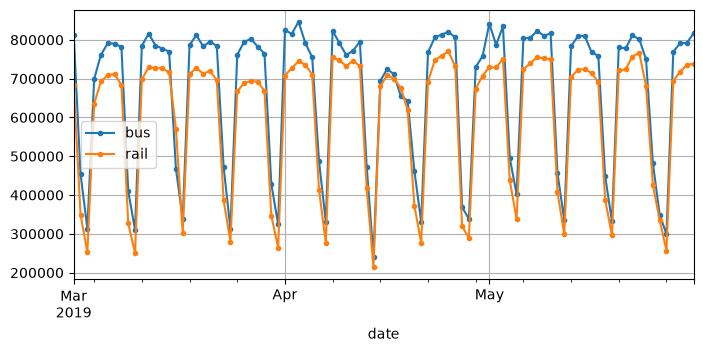

In [39]:
import matplotlib.pyplot as plt

df["2019-03":"2019-05"].plot(grid=True, marker=".", figsize=(8, 3.5))
plt.show()

## 3. Análisis de autocorrelación

La autocorrelación compara la serie con una copia rezagada. Un pico en el rezago 7 indica un ciclo semanal: cada día se parece al mismo día de la semana anterior.

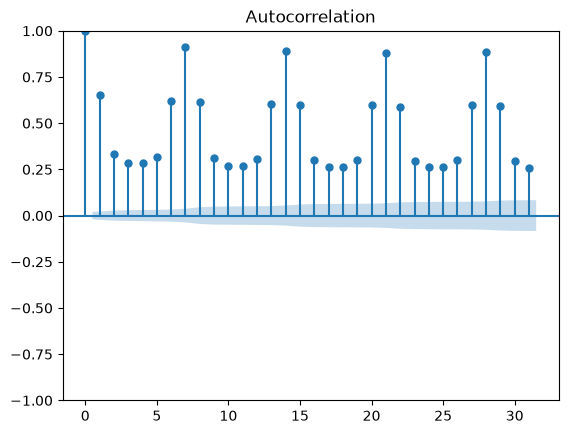

In [40]:
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(df["bus"], lags=31)
plt.show()

### Diferencia semanal

Restar el valor de hace 7 días quita el ciclo semanal. En el tren, la autocorrelación de esa diferencia es mucho más débil.

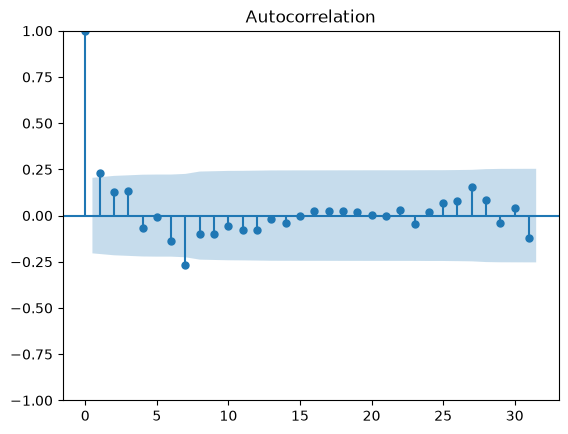

In [41]:
from statsmodels.graphics.tsaplots import plot_acf
diff_7 = df[["bus", "rail"]].diff(7)["2019-03":"2019-05"]  # diferencia de 7 días
plot_acf(diff_7["rail"], lags=31)
plt.show()

### Serie, rezago y error

Arriba, la serie y su rezago de 7 días (línea punteada). Abajo, la diferencia: el error de predecir hoy con el valor de hace una semana.

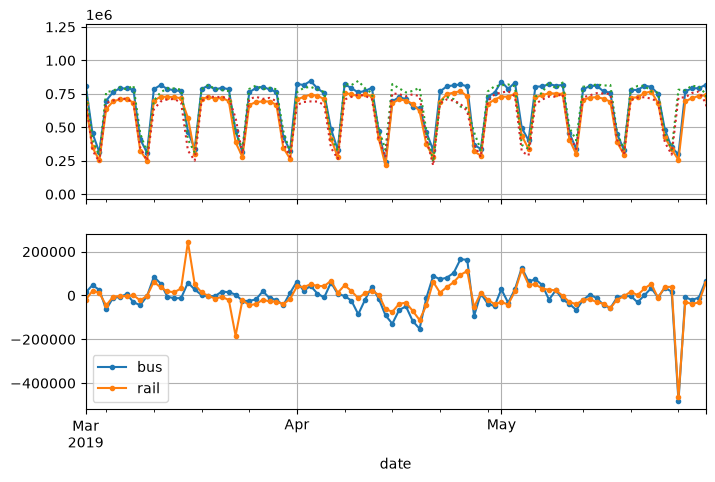

In [42]:
fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
df.plot(ax=axs[0], legend=False, marker=".")  # serie original
df.shift(7).plot(ax=axs[0], grid=True, legend=False, linestyle=":")  # rezago de 7 días
diff_7.plot(ax=axs[1], grid=True, marker=".")  # diferencia de 7 días
plt.show()

### Estacionalidad anual

El promedio mensual muestra la tendencia. La media móvil de 12 meses suaviza el ciclo del año. La diferencia de 12 meses lo elimina.

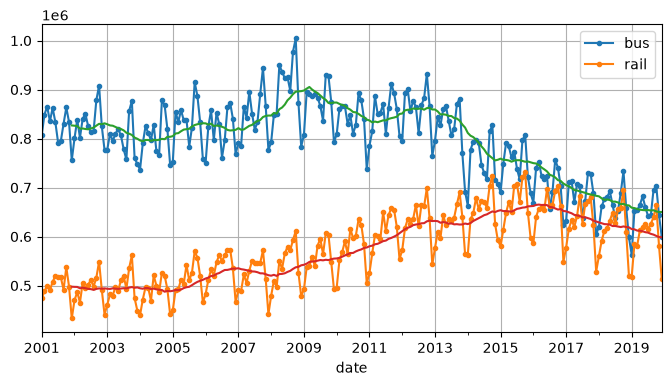

In [43]:
period = slice("2001", "2019")
df_monthly = df.select_dtypes(include="number").resample('ME').mean()  # promedio mensual
rolling_average_12_months = df_monthly.loc[period].rolling(window=12).mean()  # media móvil de 12 meses

fig, ax = plt.subplots(figsize=(8, 4))
df_monthly[period].plot(ax=ax, marker=".")
rolling_average_12_months.plot(ax=ax, grid=True, legend=False)
plt.show()

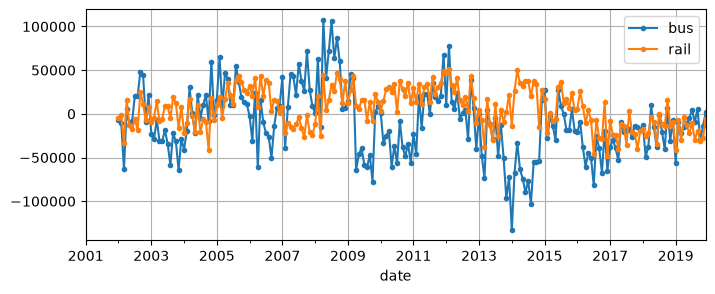

In [44]:
df_monthly.diff(12)[period].plot(grid=True, marker=".", figsize=(8, 3))  # diferencia de 12 meses
plt.show()

## 4. Pronóstico naive

El pronóstico naive semanal predice el valor de hoy con el de hace 7 días. El MAPE es el promedio del error absoluto dividido por el valor real, entre marzo y mayo de 2019.

In [45]:
targets = df[["bus", "rail"]]["2019-03":"2019-05"]
MAPE = (diff_7 / targets).abs().mean()  # error relativo medio
print(f"MAPE:\n{MAPE}")

MAPE:
bus     0.082938
rail    0.089948
dtype: float64


## 5. SARIMA

SARIMA añade estacionalidad a un ARIMA. El orden es `(1, 0, 0)` y el estacional `(0, 1, 1, 7)`: un término autorregresivo, una diferencia semanal y un término de media móvil estacional.

### Serie de tren

Pasamos la serie a frecuencia diaria, de enero a mayo de 2019. La línea vertical marca el último día observado.

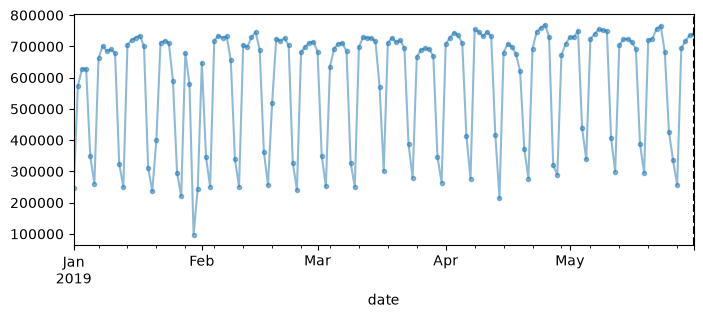

In [48]:
from statsmodels.tsa.arima.model import ARIMA

origin, today = "2019-01-01", "2019-05-31"
rail_series = df["rail"].asfreq("D")  # frecuencia diaria
rail_series = rail_series.loc[origin:today]

fig, ax = plt.subplots(figsize=(8, 3))
rail_series.plot(ax=ax, marker=".", alpha=0.5)
ax.axvline(today, color="k", linestyle="--")  # último día observado
plt.show()

### Pronóstico a 10 días

Ajustamos el modelo a toda la serie y proyectamos los siguientes 10 días. El gráfico superpone ese pronóstico a la serie observada.

In [58]:
model = ARIMA(rail_series,
              order=(1, 0, 0),              # AR(1)
              seasonal_order=(0, 1, 1, 7))  # diferencia y MA semanal
model_fit = model.fit()
y_pred = model_fit.forecast(steps=10)  # próximos 10 días
y_pred

2019-06-01    427758.626321
2019-06-02    323574.505154
2019-06-03    566686.086935
2019-06-04    720952.969714
2019-06-05    737304.722809
2019-06-06    742286.572683
2019-06-07    716657.882362
2019-06-08    413696.751280
2019-06-09    314447.139203
2019-06-10    560761.641657
Freq: D, Name: predicted_mean, dtype: float64

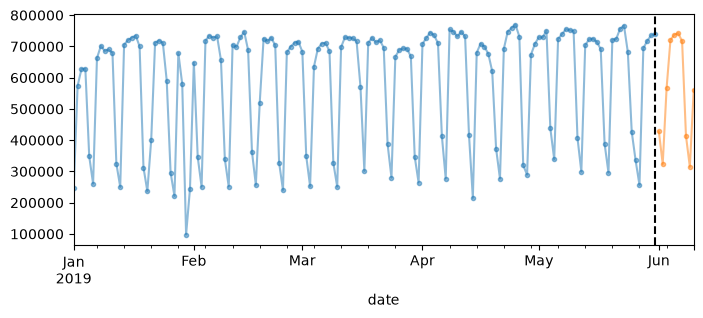

In [59]:
fig, ax = plt.subplots(figsize=(8, 3))
rail_series.plot(ax=ax, marker=".", alpha=0.5)  # serie observada
y_pred.plot(ax=ax, marker=".", alpha=0.5)       # pronóstico
ax.axvline(today, color="k", linestyle="--")    # último día observado
plt.show()

### Evaluación día a día

Cada día reentrenamos con los datos hasta ese día y predecimos solo el siguiente. El MAPE compara esas predicciones con el tren real entre marzo y mayo de 2019.

In [72]:
origin, start_date, end_date = "2019-01-01", "2019-03-01", "2019-05-31"
time_period = pd.date_range(start_date, end_date)  # días a evaluar
rail_series = df.loc[origin:end_date]["rail"].asfreq("D")

y_preds = []
for today in time_period.shift(-1):  # día anterior a cada fecha a predecir
    model = ARIMA(rail_series[origin:today],  # entrena hasta ese día
                  order=(1, 0, 0),
                  seasonal_order=(0, 1, 1, 7))
    model = model.fit()  # reentrena cada día
    y_pred = model.forecast().iloc[0]  # solo el día siguiente
    y_preds.append(y_pred)

y_preds = pd.Series(y_preds, index=time_period)
mape = ((y_preds - rail_series[time_period]) / rail_series[time_period]).abs().mean()
mape

np.float64(0.07543100728608762)